# Harmonized data interface

This notebook demonstrates how processed sensor products are registered on a shared visualization grid. Modalities are optional: a cube may contain TLS alone, any other subset, or no layers while it is being assembled.

The TLS example uses the real Ankasa PLY point cloud. Its vertices are retained as a native point-cloud `DataLayer` and aggregated to a regular voxel layer for the cube. The aggregation shown here is provisional notebook code until the TLS cube generator owns this operation.

In [19]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

from tomo_canopy.processors import TLSProcessor
from tomo_canopy.types import (
    DataCube,
    DataLayer,
    GeometryType,
    GridSpec,
    Modality,
)

## Load real TLS data and define its grid

The provider reads the binary PLY vertices through memory maps (`load=False`). This PLY also contains triangular faces, but the data interface below intentionally exposes its vertices as a point cloud. Confirm the CRS from the source metadata before combining it with other modalities; the example uses UTM zone 30N. The 1 m grid coordinates represent voxel centres.

In [20]:
TLS_CRS = "EPSG:32630"
TLS_VOXEL_SIZE = 1.0  # metres
tls_candidates = [
    Path("data/TLS/Ankasa/c01_r02_subsampled_1cm_trees_mesh.ply"),
    Path("../data/TLS/Ankasa/c01_r02_subsampled_1cm_trees_mesh.ply"),
]
TLS_PATH = next((path for path in tls_candidates if path.is_file()), tls_candidates[0])

tls_processor = TLSProcessor()
tls_mesh = tls_processor.open(TLS_PATH, crs=TLS_CRS, load=False)
tls_bounds = tls_processor.bounds(tls_mesh)

# Discard connectivity for this visualization while retaining every vertex.
tls_points = tls_mesh.drop_vars("face_vertices").rename({"vertex": "point"})
tls_points.attrs = {**tls_mesh.attrs, "geometry_type": "point_cloud"}
tls_point_layer = DataLayer(
    name="tls_points",
    data=tls_points,
    modality=Modality.TLS,
    geometry=GeometryType.POINT_CLOUD,
)

minimum = dict(zip(tls_bounds.axis.values, tls_bounds.minimum.values))
maximum = dict(zip(tls_bounds.axis.values, tls_bounds.maximum.values))
edges = {
    axis: np.arange(
        np.floor(minimum[axis] / TLS_VOXEL_SIZE) * TLS_VOXEL_SIZE,
        np.ceil(maximum[axis] / TLS_VOXEL_SIZE) * TLS_VOXEL_SIZE
        + TLS_VOXEL_SIZE,
        TLS_VOXEL_SIZE,
    )
    for axis in ("x", "y", "z")
}
centres = {
    axis: (axis_edges[:-1] + axis_edges[1:]) / 2
    for axis, axis_edges in edges.items()
}
grid = GridSpec(
    x=centres["x"], y=centres["y"], z=centres["z"], crs=TLS_CRS
)
print(f"Native TLS points: {tls_points.sizes['point']:,}")
print("Grid shape (z, y, x):", grid.shape)

Native TLS points: 6,930,014
Grid shape (z, y, x): (44, 44, 71)


## Start without any modalities

An empty cube is valid. This allows an assembly workflow to add whichever products are available.

In [21]:
cube = DataCube(grid=grid)
expected = {Modality.TLS, Modality.ALS, Modality.GEDI, Modality.TOMOGRAM}
print("Present:", sorted(cube.modalities))
print("Missing:", sorted(cube.missing_modalities(expected)))

Present: []
Missing: ['als', 'gedi', 'tls', 'tomogram']


## Add the real TLS volume

The native `tls_point_layer` remains available for point-cloud rendering and processing. `DataCube` requires rectilinear coordinates, so all real TLS vertices are counted into the 1 m grid. Both point count and binary occupancy are retained.

In [22]:
point_count, _ = np.histogramdd(
    (tls_points.z.values, tls_points.y.values, tls_points.x.values),
    bins=(edges["z"], edges["y"], edges["x"]),
)
tls_dataset = xr.Dataset(
    {
        "point_count": (
            ("z", "y", "x"), point_count.astype(np.int32)
        ),
        "occupancy": (
            ("z", "y", "x"), point_count > 0
        ),
    },
    coords=grid.coordinates,
    attrs={
        "crs": grid.crs,
        "source": str(TLS_PATH.resolve()),
        "voxel_size": TLS_VOXEL_SIZE,
        "aggregation": "point count per voxel",
    },
)
tls_layer = DataLayer(
    name="tls_occupancy",
    data=tls_dataset,
    modality=Modality.TLS,
    geometry=GeometryType.VOLUME,
)
cube.add_layer(tls_layer)

In [23]:
print("Has TLS:", cube.has_modality(Modality.TLS))
print("Has ALS:", cube.has_modality(Modality.ALS))
print("Still missing:", sorted(cube.missing_modalities(expected)))
print("TLS layers:", [layer.name for layer in cube.layers_for("tls")])

Has TLS: True
Has ALS: False
Still missing: ['als', 'gedi', 'tomogram']
TLS layers: ['tls_occupancy']


## Visualize the available TLS product

Consumers render what is present rather than assuming every modality exists.

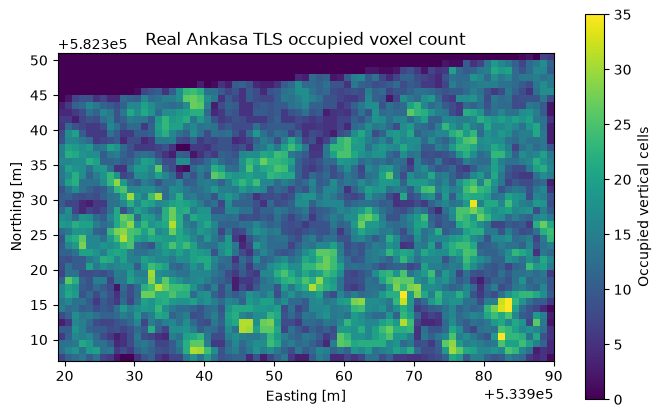

In [24]:
tls_height = tls_dataset.occupancy.sum("z")
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.pcolormesh(grid.x, grid.y, tls_height, shading="nearest")
ax.set_aspect("equal")
ax.set(
    xlabel="Easting [m]",
    ylabel="Northing [m]",
    title="Real Ankasa TLS occupied voxel count",
)
fig.colorbar(image, ax=ax, label="Occupied vertical cells")
plt.show()

## Optionally add ALS

A two-dimensional canopy-height layer may use the matching `x` and `y` subset of the three-dimensional grid. No GEDI or tomogram placeholder is needed.

In [25]:
xx, yy = np.meshgrid(grid.x, grid.y, indexing="xy")
x_scale = max(float(np.ptp(grid.x)), 1.0)
y_scale = max(float(np.ptp(grid.y)), 1.0)
canopy_height = 25.0 + 8.0 * np.exp(
    -(((xx - grid.x.mean()) / x_scale) ** 2
      + ((yy - grid.y.mean()) / y_scale) ** 2) * 8.0
)
als_dataset = xr.Dataset(
    {"canopy_height": (("y", "x"), canopy_height.astype("float32"))},
    coords={"x": grid.x, "y": grid.y},
    attrs={"crs": grid.crs},
)
cube.add_layer(
    DataLayer(
        name="als_canopy_height",
        data=als_dataset,
        modality=Modality.ALS,
        geometry=GeometryType.RASTER,
    )
)
print("Present after adding ALS:", sorted(cube.modalities))
print("Missing after adding ALS:", sorted(cube.missing_modalities(expected)))

Present after adding ALS: ['als', 'tls']
Missing after adding ALS: ['gedi', 'tomogram']


## Build the visualization dataset

`to_xarray()` combines only available layers. Variable names are prefixed with their layer names to avoid collisions.

In [26]:
visualization_data = cube.to_xarray()
visualization_data

<xarray.Dataset> Size: 701kB
Dimensions:                           (x: 71, y: 44, z: 44)
Coordinates:
  * x                                 (x) float64 568B 5.339e+05 ... 5.34e+05
  * y                                 (y) float64 352B 5.823e+05 ... 5.824e+05
  * z                                 (z) float64 352B 115.5 116.5 ... 158.5
Data variables:
    tls_occupancy__point_count        (z, y, x) int32 550kB 0 0 0 0 ... 0 0 0 0
    tls_occupancy__occupancy          (z, y, x) bool 137kB False False ... False
    als_canopy_height__canopy_height  (y, x) float32 12kB 25.15 25.16 ... 25.15
Attributes:
    crs:         EPSG:32630
    modalities:  ['als', 'tls']

## Require modalities only when necessary

Most visualization paths should adapt to available layers. An operation that specifically compares TLS against BIOMASS tomography can explicitly require both and provide a clear error otherwise.

In [27]:
try:
    cube.require_modalities(Modality.TLS, Modality.TOMOGRAM)
except ValueError as error:
    print(error)

Missing required modalities: tomogram


## Validation prevents accidental misalignment

A layer with shifted coordinates or another CRS is rejected before it reaches visualization. Reprojection and resampling belong in processors/transforms and cube generation.

In [28]:
shifted_dataset = xr.Dataset(
    {"value": (("y", "x"), np.ones((grid.y.size, grid.x.size)))},
    coords={"x": grid.x + 100.0, "y": grid.y},
    attrs={"crs": grid.crs},
)
shifted_layer = DataLayer(
    name="shifted_example",
    data=shifted_dataset,
    modality=Modality.OTHER,
    geometry=GeometryType.RASTER,
)
try:
    cube.add_layer(shifted_layer)
except ValueError as error:
    print(error)

Layer coordinate 'x' does not match the cube grid


## Add a real GEDI layer

This section queries GEDI observations from the public GFZ `gedidb` object store. The processor first exposes the native shots as a point-cloud `DataLayer`. Because `DataCube` accepts only layers aligned to a common rectilinear grid, the example then aggregates AGBD and RH98 into 1 km cells. This small aggregation is an example for exercising the interface; a reusable GEDI cube generator should eventually own that operation.

Install the optional dependencies before running this section: `python -m pip install -e '.[gedi,examples]'`. Internet access is required.

In [29]:
import geopandas as gpd
from shapely.geometry import box

from tomo_canopy.processors import GEDIProcessor

# Example area in southwest Ghana. Replace this box with the study site.
GEDI_BOUNDS = (-2.70, 5.10, -2.50, 5.30)
TARGET_CRS = "EPSG:32630"
roi = gpd.GeoDataFrame(
    geometry=[box(*GEDI_BOUNDS)],
    crs="EPSG:4326",
)

gedi_processor = GEDIProcessor()
gedi = gedi_processor.open(
    roi,
    variables=["agbd", "rh"],
    start_time="2019-01-01",
    end_time="2024-07-25",
)
print(f"Downloaded {gedi.sizes['shot_number']:,} GEDI shots")

Downloaded 21,234 GEDI shots


In [30]:
gedi_layer_native = None
gedi_projected = None

if gedi.sizes["shot_number"] == 0:
    print("No GEDI shots were found. Try a larger or different GEDI_BOUNDS.")
else:
    gedi_valid = gedi_processor.filter_valid(
        gedi, variables=["agbd", "rh"]
    )
    if gedi_valid.sizes["shot_number"] == 0:
        print("Shots were returned, but none contain both AGBD and RH data.")
    else:
        gedi_metrics = gedi_processor.add_rh_metric(
            gedi_valid, percentile=98, name="rh98"
        )
        gedi_projected = gedi_processor.reproject(
            gedi_metrics, target_crs=TARGET_CRS
        )
        gedi_layer_native = gedi_processor.to_data_layer(
            gedi_projected, name="gedi_shots"
        )
        print(gedi_layer_native)

DataLayer(name='gedi_shots', data=<xarray.Dataset> Size: 10MB
Dimensions:         (shot_number: 21234, profile_points: 101)
Coordinates:
  * shot_number     (shot_number) uint64 170kB 308180000300297325 ... 3078000...
    latitude        (shot_number) float64 170kB 5.107 5.106 5.1 ... 5.11 5.109
    longitude       (shot_number) float64 170kB -2.679 -2.679 ... -2.514 -2.514
    time            (shot_number) datetime64[ns] 170kB 2024-05-22 ... 2019-06-29
    x               (shot_number) float64 170kB 5.356e+05 ... 5.539e+05
    y               (shot_number) float64 170kB 5.645e+05 ... 5.648e+05
  * profile_points  (profile_points) int16 202B 0 1 2 3 4 5 ... 96 97 98 99 100
Data variables:
    agbd            (shot_number) float32 85kB 51.77 28.68 40.94 ... 126.2 73.8
    rh              (shot_number, profile_points) float32 9MB -3.31 ... 15.17
    rh98            (shot_number) float32 85kB 12.29 8.9 14.72 ... 19.4 14.19
Attributes: (12/13)
    source:               gedidb
    modality:

The native point layer is useful to processors and point visualizations, but its `shot_number` geometry is not cube-aligned. The next cell creates a grid from the actual projected extent and calculates cell means plus shot counts.

In [31]:
gedi_cube = None
GEDI_CELL_SIZE = 1_000.0  # metres in EPSG:32630

if gedi_projected is not None:
    x_values = np.asarray(gedi_projected.x.values)
    y_values = np.asarray(gedi_projected.y.values)
    x_start = np.floor(x_values.min() / GEDI_CELL_SIZE) * GEDI_CELL_SIZE
    x_stop = np.ceil(x_values.max() / GEDI_CELL_SIZE) * GEDI_CELL_SIZE
    y_start = np.floor(y_values.min() / GEDI_CELL_SIZE) * GEDI_CELL_SIZE
    y_stop = np.ceil(y_values.max() / GEDI_CELL_SIZE) * GEDI_CELL_SIZE
    x_edges = np.arange(x_start, x_stop + GEDI_CELL_SIZE, GEDI_CELL_SIZE)
    y_edges = np.arange(y_start, y_stop + GEDI_CELL_SIZE, GEDI_CELL_SIZE)
    if x_edges.size < 2:
        x_edges = np.array([x_start, x_start + GEDI_CELL_SIZE])
    if y_edges.size < 2:
        y_edges = np.array([y_start, y_start + GEDI_CELL_SIZE])

    def cell_mean(values):
        values = np.asarray(values)
        valid = np.isfinite(values)
        totals, _, _ = np.histogram2d(
            y_values[valid], x_values[valid],
            bins=(y_edges, x_edges), weights=values[valid],
        )
        counts, _, _ = np.histogram2d(
            y_values[valid], x_values[valid], bins=(y_edges, x_edges)
        )
        return np.divide(
            totals, counts, out=np.full_like(totals, np.nan), where=counts > 0
        )

    shot_count, _, _ = np.histogram2d(
        y_values, x_values, bins=(y_edges, x_edges)
    )
    x_centres = (x_edges[:-1] + x_edges[1:]) / 2
    y_centres = (y_edges[:-1] + y_edges[1:]) / 2
    gedi_raster = xr.Dataset(
        data_vars={
            "agbd_mean": (("y", "x"), cell_mean(gedi_projected.agbd.values)),
            "rh98_mean": (("y", "x"), cell_mean(gedi_projected.rh98.values)),
            "shot_count": (("y", "x"), shot_count.astype(np.int64)),
        },
        coords={"x": x_centres, "y": y_centres},
        attrs={
            "crs": TARGET_CRS,
            "cell_size": GEDI_CELL_SIZE,
            "aggregation": "arithmetic mean per grid cell",
        },
    )
    gedi_grid = GridSpec(
        x=x_centres, y=y_centres, z=np.array([0.0]), crs=TARGET_CRS
    )
    gedi_raster_layer = DataLayer(
        name="gedi_metrics",
        data=gedi_raster,
        modality=Modality.GEDI,
        geometry=GeometryType.RASTER,
    )
    gedi_cube = DataCube(grid=gedi_grid)
    gedi_cube.add_layer(gedi_raster_layer)
    display(gedi_cube.to_xarray())
    print("GEDI modality present:", gedi_cube.has_modality(Modality.GEDI))

<xarray.Dataset> Size: 13kB
Dimensions:                   (x: 23, y: 23, z: 1)
Coordinates:
  * x                         (x) float64 184B 5.335e+05 5.345e+05 ... 5.555e+05
  * y                         (y) float64 184B 5.635e+05 5.645e+05 ... 5.855e+05
  * z                         (z) float64 8B 0.0
Data variables:
    gedi_metrics__agbd_mean   (y, x) float64 4kB 72.0 82.44 ... 158.0 122.6
    gedi_metrics__rh98_mean   (y, x) float64 4kB 15.65 15.16 ... 25.38 22.26
    gedi_metrics__shot_count  (y, x) int64 4kB 14 27 11 10 13 ... 52 68 37 85 28
Attributes:
    crs:         EPSG:32630
    modalities:  ['gedi']

GEDI modality present: True


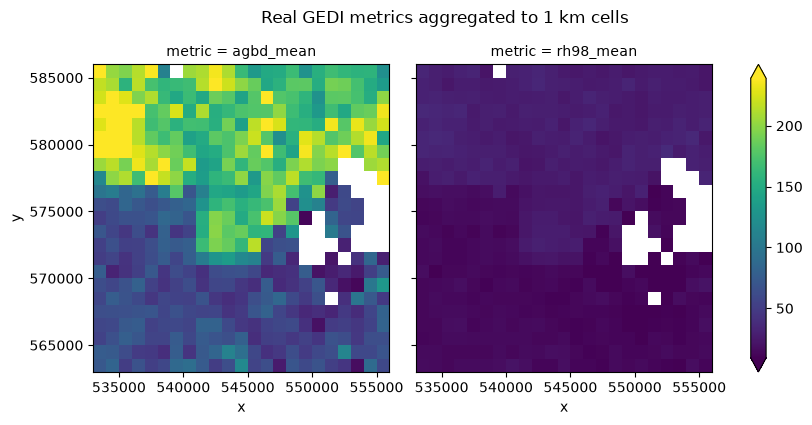

In [32]:
if gedi_cube is not None:
    axes = gedi_raster[["agbd_mean", "rh98_mean"]].to_array("metric").plot(
        col="metric", col_wrap=2, robust=True, size=4
    )
    axes.fig.suptitle("Real GEDI metrics aggregated to 1 km cells", y=1.05)